# Class 5: Supervised text classification

Last class, we assigned dictionary weights by hand. Today we learn word weights from labelled examples and compare them with that dictionary.

We use the same Pang and Lee Rotten Tomatoes sentence-polarity dataset. Its labels come from the source review's *fresh* or *rotten* status, so they are reference labels for the review rather than independent annotations of every snippet.

This notebook requires NumPy, Matplotlib, and scikit-learn. It reads the local data supplied with Class 4 and runs without downloading data or models.


In [1]:
from pathlib import Path
import re
import sys
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve,
    average_precision_score,
)

SEED = 2026
plt.rcParams.update({"figure.dpi": 110, "font.size": 14, "axes.titlesize": 16, "axes.labelsize": 14, "axes.spines.top": False, "axes.spines.right": False})
print("Python:", sys.version.split()[0], "| scikit-learn:", sklearn.__version__)


Python: 3.13.5 | scikit-learn: 1.7.2


## Load the labelled corpus

Label 1 means a positive source review and label 0 means a negative source review. The files contain one lowercase snippet per line. The original files use Latin-1 encoding.


In [2]:
candidates = [Path("meeting_slides/meeting_05").resolve(), Path(".").resolve()]
session_dir = next(
    p for p in candidates
    if (p.parent / "meeting_04/data/rotten_tomatoes/rt-polarity.pos").exists()
)
data_dir = session_dir.parent / "meeting_04/data/rotten_tomatoes"
figure_dir = session_dir / "figures"
figure_dir.mkdir(exist_ok=True)

negative = [line.rstrip("\r") for line in (data_dir / "rt-polarity.neg").read_text(encoding="latin-1").split("\n") if line.strip()]
positive = [line.rstrip("\r") for line in (data_dir / "rt-polarity.pos").read_text(encoding="latin-1").split("\n") if line.strip()]
assert len(negative) == len(positive) == 5331
texts = np.array(negative + positive, dtype=object)
labels = np.array([0] * len(negative) + [1] * len(positive))
print(f"{len(texts):,} snippets: {len(negative):,} negative and {len(positive):,} positive.")


10,662 snippets: 5,331 negative and 5,331 positive.


## Split before fitting a representation

We use a seeded, stratified split with approximately 60% training, 20% validation, and 20% test data. Training data estimate word probabilities or coefficients. Validation data choose settings. The test set provides the final comparison.

This is a teaching split at the snippet level. In a study, texts from the same review, author, or source may need to stay in one group. These files do not provide those group identifiers.


In [3]:
development_ids, test_ids = train_test_split(
    np.arange(len(texts)), test_size=0.2, random_state=SEED, stratify=labels
)
train_ids, validation_ids = train_test_split(
    development_ids, test_size=0.25, random_state=SEED, stratify=labels[development_ids]
)

X_train, y_train = texts[train_ids], labels[train_ids]
X_validation, y_validation = texts[validation_ids], labels[validation_ids]
X_development, y_development = texts[development_ids], labels[development_ids]
X_test, y_test = texts[test_ids], labels[test_ids]

for name, ids in [("Training", train_ids), ("Validation", validation_ids), ("Test", test_ids)]:
    print(f"{name:11} n={len(ids):,}; positive={sum(labels[ids]):,}; negative={sum(labels[ids] == 0):,}")
assert not (set(train_ids) & set(validation_ids) or set(development_ids) & set(test_ids))


Training    n=6,396; positive=3,198; negative=3,198
Validation  n=2,133; positive=1,066; negative=1,067
Test        n=2,133; positive=1,067; negative=1,066


## Dictionary weights and learned weights

For a document vector $\mathbf{x}$, a dictionary can assign weights $a_w$ manually:

$$s_D(d)=b+\sum_w a_w x_w.$$

A linear classifier uses the same weighted-sum structure but estimates the weights from labelled data.

For multinomial Naive Bayes, the log posterior odds are

$$
\log\frac{P(y=1\mid\mathbf{x})}{P(y=0\mid\mathbf{x})}
=\log\frac{\pi_1}{\pi_0}
+\sum_w x_w\log\frac{\theta_{1w}}{\theta_{0w}}.
$$

Each class has a word distribution $\boldsymbol{\theta}_c$. Smoothing makes every vocabulary term's probability positive. Tokens are modelled as independent draws conditional on the class and document length; the resulting count components are constrained to sum to that length.


## Classification, regression, and fitting a model

Classification predicts a category. Regression predicts a number. Both start with labelled feature-outcome pairs, but the output and loss differ.

For regression, mean squared error is

$$
\mathrm{MSE}(\theta)=\frac{1}{N}\sum_{i=1}^{N}
\left[y_i-f(\mathbf{x}_i;\theta)\right]^2.
$$

For the invented data $x=(1,2,3)$ and $y=(2,4,6)$, suppose $f_\theta(x)=\theta x$. Then

$$
\mathrm{MSE}(\theta)=\frac{14}{3}(\theta-2)^2,
\qquad
\frac{\partial\mathrm{MSE}}{\partial\theta}=\frac{28}{3}(\theta-2).
$$

The minimum is at $\theta=2$. This example illustrates fitting, before returning to text classification.


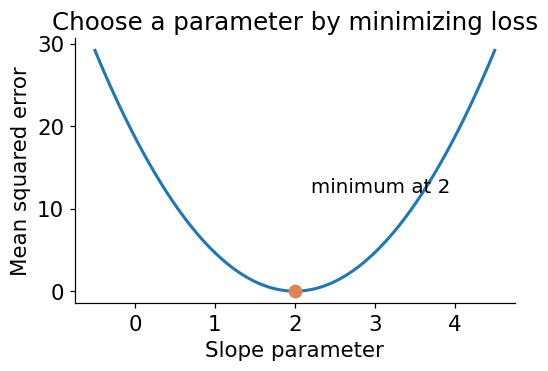

In [4]:
toy_regression_x = np.array([1., 2., 3.])
toy_regression_y = np.array([2., 4., 6.])
theta_grid = np.linspace(-0.5, 4.5, 200)
loss_grid = np.mean(
    (toy_regression_y[None, :] - theta_grid[:, None] * toy_regression_x[None, :]) ** 2,
    axis=1,
)
fig, ax = plt.subplots(figsize=(5.0, 3.6))
ax.plot(theta_grid, loss_grid, linewidth=2)
ax.scatter([2], [0], color="#dd8452", s=65, zorder=3)
ax.annotate("minimum at 2", (2, 0), xytext=(2.2, 12), fontsize=13)
ax.set(xlabel="Slope parameter", ylabel="Mean squared error", title="Choose a parameter by minimizing loss")
fig.tight_layout()
fig.savefig(figure_dir / "squared_error.png", dpi=180)
plt.show()
assert np.allclose(loss_grid, (14 / 3) * (theta_grid - 2) ** 2)


## A simple optimization step

Gradient descent updates parameters in the direction that lowers the loss:

$$
\theta^{(t+1)}=\theta^{(t)}-\eta\,\nabla_\theta\mathcal{L}(\theta^{(t)}).
$$

The step size $\eta$ controls how far the parameter moves. The following code uses plain gradient descent on the small regression example. The logistic regression implementation later uses L-BFGS rather than these exact updates.


In [5]:
theta = 0.0
step_size = 0.1
for iteration in range(5):
    loss = np.mean((toy_regression_y - theta * toy_regression_x) ** 2)
    print(f"step={iteration}, theta={theta:.6f}, MSE={loss:.6f}")
    gradient = (28 / 3) * (theta - 2)
    theta -= step_size * gradient
assert np.isclose(0 - step_size * (28 / 3) * (0 - 2), 28 / 15)


step=0, theta=0.000000, MSE=18.666667
step=1, theta=1.866667, MSE=0.082963
step=2, theta=1.991111, MSE=0.000369
step=3, theta=1.999407, MSE=0.000002
step=4, theta=1.999960, MSE=0.000000


## Keep the Class 4 dictionary as a baseline

The word lists and tie rule are the same as in Class 4. A zero score is classified as negative. This baseline is fixed before inspecting the new test split.


In [6]:
positive_terms = {
    "beautiful", "best", "brilliant", "charming", "compelling", "enjoyable",
    "entertaining", "excellent", "fantastic", "funny", "good", "great",
    "moving", "wonderful",
}
negative_terms = {
    "awful", "bad", "boring", "disappointing", "dull", "poor", "ridiculous",
    "stupid", "terrible", "waste", "worst",
}

def dictionary_scores(documents):
    return np.array([
        sum(w in positive_terms for w in re.findall(r"[a-z]+", text.lower()))
        - sum(w in negative_terms for w in re.findall(r"[a-z]+", text.lower()))
        for text in documents
    ])

def metrics(y_true, predictions):
    return {
        "accuracy": accuracy_score(y_true, predictions),
        "precision": precision_score(y_true, predictions, zero_division=0),
        "recall": recall_score(y_true, predictions, zero_division=0),
        "F1": f1_score(y_true, predictions, zero_division=0),
    }

print("Dictionary validation metrics:", metrics(y_validation, (dictionary_scores(X_validation) > 0).astype(int)))


Dictionary validation metrics: {'accuracy': 0.5485232067510548, 'precision': 0.6872727272727273, 'recall': 0.1772983114446529, 'F1': 0.28187919463087246}


## A small, fully worked Naive Bayes prediction

This invented example has three vocabulary terms. Both classes contain 15 training tokens and have prior probability 0.5. With additive smoothing $\alpha=1$,

$$\theta_{cw}=\frac{n_{cw}+\alpha}{\sum_v n_{cv}+\alpha V}.$$

Predict the two-token text *great plot*. The multinomial coefficient is identical for both classes and cancels in their posterior ratio.


In [7]:
toy_counts = np.array([[1, 7, 7], [8, 2, 5]])  # negative, positive; great, dull, plot
toy_probabilities = (toy_counts + 1) / (toy_counts.sum(axis=1, keepdims=True) + 3)
toy_x = np.array([1, 0, 1])
toy_log_scores = np.log(0.5) + (toy_x * np.log(toy_probabilities)).sum(axis=1)
toy_posterior = np.exp(toy_log_scores - np.max(toy_log_scores))
toy_posterior /= toy_posterior.sum()
print("Smoothed probabilities (negative, positive):")
print(toy_probabilities)
print("Log posterior odds:", toy_log_scores[1] - toy_log_scores[0])
print("Positive posterior:", toy_posterior[1])
assert np.allclose(toy_probabilities.sum(axis=1), 1)
assert np.isclose(toy_posterior[1], 27 / 35)


Smoothed probabilities (negative, positive):
[[0.11111111 0.44444444 0.44444444]
 [0.5        0.16666667 0.33333333]]
Log posterior odds: 1.2163953243244934
Positive posterior: 0.7714285714285715


## Counts and Naive Bayes

Each pipeline fits its vocabulary on training data only. The minimum document frequency of 2 drops terms appearing in fewer than two training snippets. We keep stopwords because they may matter for sentiment.

We compare three smoothing values on validation data and select by positive-class F1 at the default decision threshold.


In [8]:
TOKEN_PATTERN = r"(?u)\b[a-z]+\b"

def nb_pipeline(alpha):
    return Pipeline([
        ("features", CountVectorizer(token_pattern=TOKEN_PATTERN, min_df=2)),
        ("classifier", MultinomialNB(alpha=alpha)),
    ])

nb_trials = []
for alpha in (0.1, 1.0, 10.0):
    model = nb_pipeline(alpha).fit(X_train, y_train)
    validation_f1 = f1_score(y_validation, model.predict(X_validation))
    nb_trials.append((alpha, validation_f1))
    print(f"alpha={alpha:4.1f} | validation F1={validation_f1:.3f}")
best_alpha = max(nb_trials, key=lambda trial: trial[1])[0]
print("Selected alpha:", best_alpha)


alpha= 0.1 | validation F1=0.747


alpha= 1.0 | validation F1=0.761
alpha=10.0 | validation F1=0.745
Selected alpha: 1.0


## Logistic regression learns weights directly

For features $\mathbf{x}$, logistic regression gives

$$
z=b+\mathbf{x}^{\mathsf{T}}\boldsymbol{\beta},
\qquad
p(y=1\mid\mathbf{x})=\frac{1}{1+\exp(-z)}.
$$

It fits coefficients by minimizing log loss plus a penalty:

$$
\mathcal{L}
=-\frac{1}{N}\sum_{i=1}^{N}
\left[y_i\log p_i+(1-y_i)\log(1-p_i)\right]
+\frac{\lambda}{2}\|\boldsymbol{\beta}\|_2^2.
$$

The penalty controls large coefficients. In scikit-learn, smaller C means stronger regularization. The exact scaling convention for the objective depends on the implementation. Predictive coefficients are not causal effects.


In [9]:
def logistic_pipeline(C, ngram_range=(1, 1)):
    return Pipeline([
        ("features", TfidfVectorizer(token_pattern=TOKEN_PATTERN, min_df=2, ngram_range=ngram_range)),
        ("classifier", LogisticRegression(C=C, solver="lbfgs", max_iter=1000, random_state=SEED)),
    ])

logistic_trials = []
for ngram_range in [(1, 1), (1, 2)]:
    for C in (0.01, 0.1, 1.0, 10.0, 100.0):
        model = logistic_pipeline(C, ngram_range).fit(X_train, y_train)
        training_f1 = f1_score(y_train, model.predict(X_train))
        validation_f1 = f1_score(y_validation, model.predict(X_validation))
        logistic_trials.append({
            "ngram_range": ngram_range, "C": C,
            "training_F1": training_f1, "validation_F1": validation_f1,
        })
        print(f"ngrams={ngram_range}, C={C:6.2f} | train F1={training_f1:.3f}, validation F1={validation_f1:.3f}")

best_unigram = max((t for t in logistic_trials if t["ngram_range"] == (1, 1)), key=lambda t: t["validation_F1"])
best_bigram = max((t for t in logistic_trials if t["ngram_range"] == (1, 2)), key=lambda t: t["validation_F1"])
selected_representation = max([best_unigram, best_bigram], key=lambda t: t["validation_F1"])
print("Selected representation from validation data:", selected_representation)


ngrams=(1, 1), C=  0.01 | train F1=0.748, validation F1=0.684


ngrams=(1, 1), C=  0.10 | train F1=0.785, validation F1=0.704
ngrams=(1, 1), C=  1.00 | train F1=0.887, validation F1=0.736


ngrams=(1, 1), C= 10.00 | train F1=0.980, validation F1=0.743


ngrams=(1, 1), C=100.00 | train F1=0.998, validation F1=0.730


ngrams=(1, 2), C=  0.01 | train F1=0.785, validation F1=0.692


ngrams=(1, 2), C=  0.10 | train F1=0.816, validation F1=0.708


ngrams=(1, 2), C=  1.00 | train F1=0.921, validation F1=0.734


ngrams=(1, 2), C= 10.00 | train F1=0.998, validation F1=0.755


ngrams=(1, 2), C=100.00 | train F1=1.000, validation F1=0.754
Selected representation from validation data: {'ngram_range': (1, 2), 'C': 10.0, 'training_F1': 0.9979652527782126, 'validation_F1': 0.7548928238583411}


## Fit a linear support vector machine

A linear SVM learns a boundary $z=\mathbf{w}^{\mathsf T}\mathbf{x}+b$. It uses a margin-based objective. For labels $t_i\in\{-1,+1\}$, hinge loss is

$$
\ell_{\mathrm{hinge}}(t_i,z_i)=\max(0,1-t_i z_i).
$$

The software accepts our 0/1 labels and handles the corresponding binary classes internally. Its decision score is not a predicted probability. We use the same unigram TF-IDF features as logistic regression and choose C using validation F1.


In [10]:
def svm_pipeline(C):
    return Pipeline([
        ("features", TfidfVectorizer(token_pattern=TOKEN_PATTERN, min_df=2)),
        ("classifier", LinearSVC(
            C=C, loss="hinge", dual=True, max_iter=20000,
            random_state=SEED,
        )),
    ])

svm_trials = []
for C in (0.1, 1.0, 10.0):
    model = svm_pipeline(C).fit(X_train, y_train)
    validation_f1 = f1_score(y_validation, model.predict(X_validation))
    svm_trials.append((C, validation_f1))
    print(f"Linear SVM C={C:g}: validation F1={validation_f1:.3f}")
best_svm_C = max(svm_trials, key=lambda trial: trial[1])[0]
print("Selected SVM C:", best_svm_C)


Linear SVM C=0.1: validation F1=0.702
Linear SVM C=1: validation F1=0.742


Linear SVM C=10: validation F1=0.710
Selected SVM C: 1.0


## Training performance and generalization

Inspect both curves. A rising training score does not guarantee a better validation score. The gap is evidence that flexibility needs to be controlled; it is not a full mathematical bias-variance decomposition.


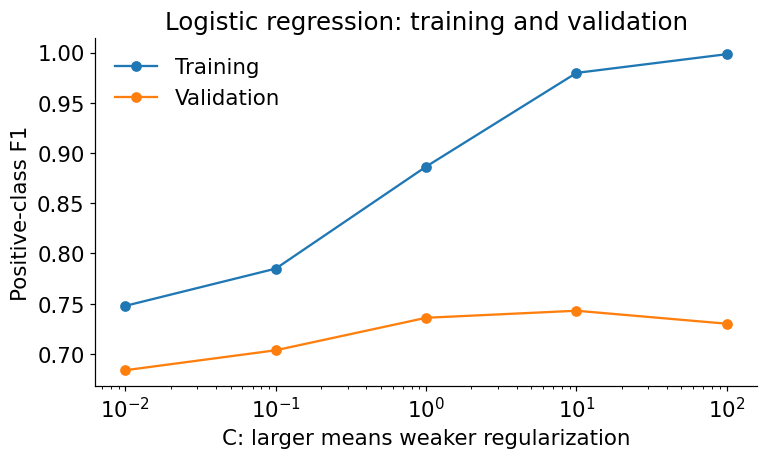

In [11]:
fig, ax = plt.subplots(figsize=(7.2, 4.4))
unigram_trials = [t for t in logistic_trials if t["ngram_range"] == (1, 1)]
ax.plot([t["C"] for t in unigram_trials], [t["training_F1"] for t in unigram_trials], "o-", label="Training")
ax.plot([t["C"] for t in unigram_trials], [t["validation_F1"] for t in unigram_trials], "o-", label="Validation")
ax.set_xscale("log")
ax.set(xlabel="C: larger means weaker regularization", ylabel="Positive-class F1",
       title="Logistic regression: training and validation")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(figure_dir / "regularization.png", dpi=180)
plt.show()


## A geometric view of the linear boundary

This invented six-point dataset has two count features. The boundary is $x_1-x_2=0$, so $\mathbf{w}=(1,-1)$ and $b=0$. Points below the diagonal receive a positive label, and points above it receive a negative label.

In two dimensions a hyperplane is a line. In a text vocabulary, the same equation can involve thousands of features.


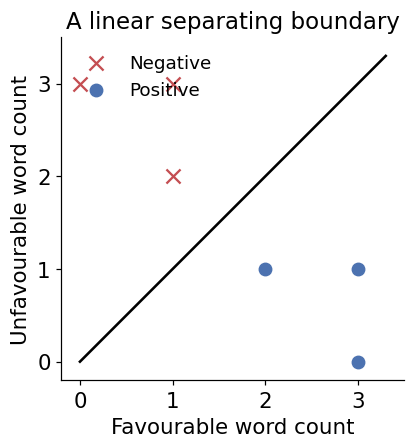

In [12]:
geometry_positive = np.array([[2, 1], [3, 1], [3, 0]])
geometry_negative = np.array([[1, 2], [1, 3], [0, 3]])

def geometry_axes():
    fig, ax = plt.subplots(figsize=(5.2, 4.3))
    ax.scatter(geometry_negative[:, 0], geometry_negative[:, 1],
               color="#c44e52", marker="x", s=85, label="Negative")
    ax.scatter(geometry_positive[:, 0], geometry_positive[:, 1],
               color="#4c72b0", s=65, label="Positive")
    ax.set(xlim=(-0.2, 3.5), ylim=(-0.2, 3.5), aspect="equal",
           xlabel="Favourable word count", ylabel="Unfavourable word count")
    ax.set_xticks([0, 1, 2, 3])
    ax.set_yticks([0, 1, 2, 3])
    return fig, ax

fig, ax = geometry_axes()
ax.plot([0, 3.3], [0, 3.3], color="black", linewidth=1.7)
ax.legend(frameon=False, loc="upper left", fontsize=12)
ax.set_title("A linear separating boundary", fontsize=15)
fig.tight_layout()
fig.savefig(figure_dir / "linear_boundary.png", dpi=180)
plt.show()


## Signed distance, margin, and support vectors

The signed geometric distance is

$$d_i=\frac{\mathbf{w}^{\mathsf T}\mathbf{x}_i+b}{\|\mathbf{w}\|}.$$

For $\mathbf{x}=(2,1)$ it is $1/\sqrt{2}\approx0.707$. The closest positive and negative points have scores $+1$ and $-1$. Their supporting lines have equations $x_1-x_2=\pm1$, so the total margin width is $2/\sqrt{2}=\sqrt{2}$.

The circled points are the hard-margin support vectors. With soft margins, observations inside a margin or on the wrong side can also influence the fitted boundary.


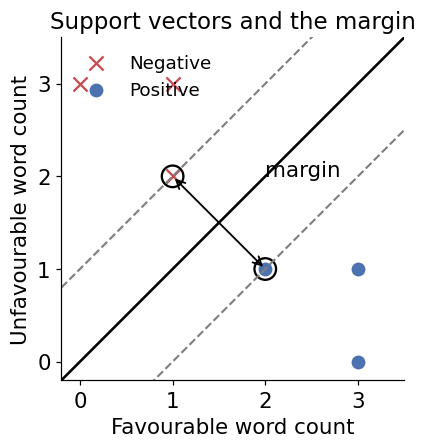

In [13]:
fig, ax = geometry_axes()
grid = np.linspace(-0.2, 3.5, 200)
ax.plot(grid, grid, color="black", linewidth=1.7)
ax.plot(grid, grid - 1, color="grey", linestyle="--", linewidth=1.4)
ax.plot(grid, grid + 1, color="grey", linestyle="--", linewidth=1.4)
ax.scatter([2, 1], [1, 2], s=200, facecolors="none", edgecolors="black", linewidth=1.5)
ax.annotate("", xy=(2, 1), xytext=(1, 2),
            arrowprops={"arrowstyle": "<->", "color": "black", "lw": 1.2})
ax.text(2.0, 2.0, "margin", fontsize=14)
ax.legend(frameon=False, loc="upper left", fontsize=12)
ax.set_title("Support vectors and the margin", fontsize=15)
fig.tight_layout()
fig.savefig(figure_dir / "svm_margin.png", dpi=180)
plt.show()
assert np.isclose(2 / np.linalg.norm([1, -1]), np.sqrt(2))


## Cross-validation keeps feature fitting inside each fold

Here is a three-fold cross-validation demonstration on the training set. Each fold fits a fresh vocabulary, IDF values, and classifier because we pass a complete pipeline.

The setting below has already been chosen using the separate validation set. These fold scores are an additional illustration of variation, rather than a new independent final evaluation.


In [14]:
folds = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
fold_scores = cross_val_score(
    logistic_pipeline(best_unigram["C"]),
    X_train, y_train, cv=folds, scoring="f1", n_jobs=1,
)
print("Fold F1 scores:", np.round(fold_scores, 3))
print(f"Mean={fold_scores.mean():.3f}, standard deviation={fold_scores.std():.3f}")


Fold F1 scores: [0.734 0.74  0.756]
Mean=0.743, standard deviation=0.009


## Refit chosen settings, then evaluate on the same test snippets

After settings have been selected, we refit on the combined training and validation set. All comparisons use the same held-out examples. Do not revise the settings after inspecting these results.

The majority-class baseline resolves a training-label tie in favour of the negative class. We report precision, recall, and F1 with the positive class as 1.


In [15]:
final_nb = nb_pipeline(best_alpha).fit(X_development, y_development)
final_logistic = logistic_pipeline(best_unigram["C"]).fit(X_development, y_development)
final_bigram = logistic_pipeline(best_bigram["C"], (1, 2)).fit(X_development, y_development)
final_svm = svm_pipeline(best_svm_C).fit(X_development, y_development)
majority = DummyClassifier(strategy="most_frequent").fit(np.zeros((len(X_development), 1)), y_development)

predictions = {
    "Majority": majority.predict(np.zeros((len(X_test), 1))),
    "Dictionary": (dictionary_scores(X_test) > 0).astype(int),
    "Naive Bayes": final_nb.predict(X_test),
    "Linear SVM": final_svm.predict(X_test),
    "Logit, unigrams": final_logistic.predict(X_test),
    "Logit, uni+bigrams": final_bigram.predict(X_test),
}
test_results = {name: metrics(y_test, prediction) for name, prediction in predictions.items()}
print(f"{'Method':22} {'Accuracy':>9} {'Precision':>10} {'Recall':>9} {'F1':>9}")
for name, result in test_results.items():
    print(f"{name:22} {result['accuracy']:9.3f} {result['precision']:10.3f} {result['recall']:9.3f} {result['F1']:9.3f}")


Method                  Accuracy  Precision    Recall        F1
Majority                   0.500      0.000     0.000     0.000
Dictionary                 0.546      0.671     0.182     0.286
Naive Bayes                0.772      0.784     0.750     0.767
Linear SVM                 0.760      0.773     0.739     0.755
Logit, unigrams            0.767      0.775     0.754     0.764
Logit, uni+bigrams         0.776      0.778     0.774     0.776


## Compare precision and recall across thresholds

For the dictionary, use the signed word-count score. For Naive Bayes and logistic regression, use the positive-class probability. For the SVM, use its decision score, which is not a probability. Every point changes the threshold; the stars show each method's default classification rule.

Average precision is a summary of the ranking, not a calibration check. These curves are a final comparison, so a new threshold should be chosen on validation data rather than here.


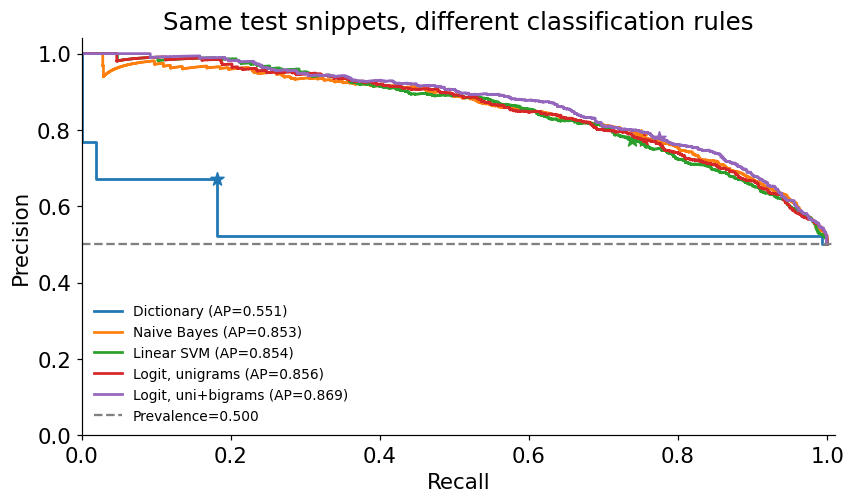

In [16]:
test_scores = {
    "Dictionary": dictionary_scores(X_test),
    "Naive Bayes": final_nb.predict_proba(X_test)[:, 1],
    "Linear SVM": final_svm.decision_function(X_test),
    "Logit, unigrams": final_logistic.predict_proba(X_test)[:, 1],
    "Logit, uni+bigrams": final_bigram.predict_proba(X_test)[:, 1],
}
fig, ax = plt.subplots(figsize=(8.0, 4.8))
for name, scores in test_scores.items():
    precision, recall, _ = precision_recall_curve(y_test, scores)
    ap = average_precision_score(y_test, scores)
    line, = ax.step(recall, precision, where="post", label=f"{name} (AP={ap:.3f})", linewidth=1.8)
    point = test_results[name]
    ax.scatter(point["recall"], point["precision"], marker="*", s=80, color=line.get_color())
ax.axhline(y_test.mean(), linestyle="--", color="grey", label=f"Prevalence={y_test.mean():.3f}")
ax.set(xlim=(0, 1.01), ylim=(0, 1.04), xlabel="Recall", ylabel="Precision",
       title="Same test snippets, different classification rules")
ax.legend(frameon=False, fontsize=9, loc="lower left")
fig.tight_layout()
fig.savefig(figure_dir / "pr_comparison.png", dpi=180)
plt.show()


## Inspect the learned word weights

These are the strongest positive and negative unigram coefficients from the fitted TF-IDF logistic model. They indicate predictive associations conditional on the other features and on this representation. Compare them with the small Class 4 word list.


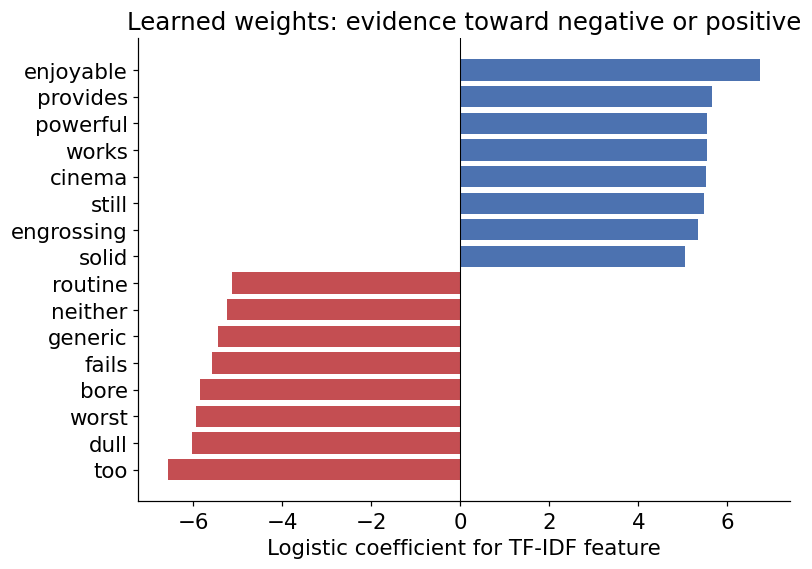

In [17]:
feature_names = final_logistic["features"].get_feature_names_out()
coefficients = final_logistic["classifier"].coef_[0]
indices = np.concatenate([np.argsort(coefficients)[:8], np.argsort(coefficients)[-8:]])
order = indices[np.argsort(coefficients[indices])]
fig, ax = plt.subplots(figsize=(7.5, 5.4))
ax.barh(feature_names[order], coefficients[order],
        color=["#c44e52" if coefficients[i] < 0 else "#4c72b0" for i in order])
ax.axvline(0, color="black", linewidth=0.7)
ax.set(xlabel="Logistic coefficient for TF-IDF feature",
       title="Learned weights: evidence toward negative or positive")
fig.tight_layout()
fig.savefig(figure_dir / "learned_weights.png", dpi=180)
plt.show()


## Confusion matrices on the shared test set

The row is the source-review label and the column is the prediction. A higher overall score can still hide a particular error type.


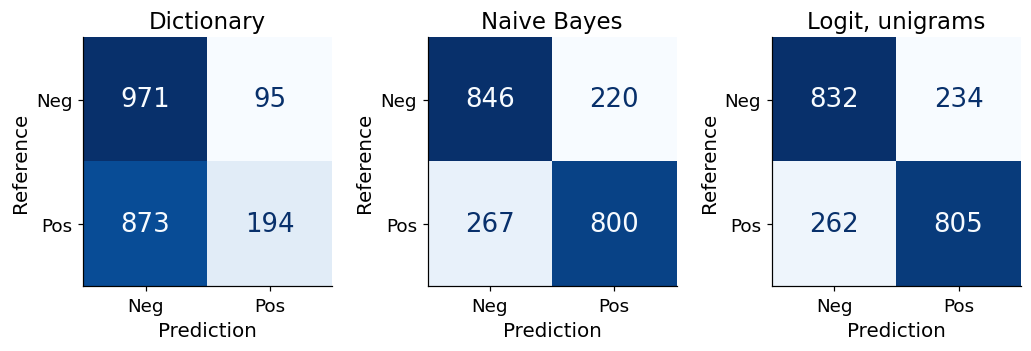

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(9.6, 3.8))
for ax, name in zip(axes, ["Dictionary", "Naive Bayes", "Logit, unigrams"]):
    matrix = confusion_matrix(y_test, predictions[name], labels=[0, 1])
    ConfusionMatrixDisplay(matrix, display_labels=["Neg", "Pos"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d"
    )
    ax.set_title(name, fontsize=15)
    ax.set_ylabel("Reference", fontsize=13)
    ax.set_xlabel("Prediction", fontsize=13)
    ax.tick_params(labelsize=12)
    for annotation in ax.texts:
        annotation.set_fontsize(17)
fig.tight_layout()
fig.savefig(figure_dir / "confusion_comparison.png", dpi=180)
plt.show()


## Read mistakes and disagreements

The same snippet may be missed by a dictionary and recognised by a learned model. A learned model can also make its own systematic mistakes. Review source-label disagreement, negation, irony, and missing context.


In [19]:
dictionary_wrong = predictions["Dictionary"] != y_test
logistic_right = predictions["Logit, unigrams"] == y_test
print("DICTIONARY WRONG, LOGISTIC REGRESSION RIGHT")
for i in np.flatnonzero(dictionary_wrong & logistic_right)[:8]:
    print(f"[source label={y_test[i]}, dictionary={predictions['Dictionary'][i]}, logit={predictions['Logit, unigrams'][i]}] {X_test[i]}")

print("\nLOGISTIC REGRESSION ERRORS")
for i in np.flatnonzero(~logistic_right)[:8]:
    print(f"[source label={y_test[i]}, logit={predictions['Logit, unigrams'][i]}] {X_test[i]}")


DICTIONARY WRONG, LOGISTIC REGRESSION RIGHT
[source label=1, dictionary=0, logit=1] polished , well-structured film . 
[source label=1, dictionary=0, logit=1] wonder , hope and magic can never escape the heart of the boy when the right movie comes along , especially if it begins with the name of star wars
[source label=1, dictionary=0, logit=1] may not be a breakthrough in filmmaking , but it is unwavering and arresting . 
[source label=1, dictionary=0, logit=1] vera has created a provocative , absorbing drama that reveals the curse of a self-hatred instilled by rigid social mores . 
[source label=1, dictionary=0, logit=1] it's a count for our times . 
[source label=1, dictionary=0, logit=1] old-fashioned but thoroughly satisfying entertainment . 
[source label=1, dictionary=0, logit=1] shot in rich , shadowy black-and-white , devils chronicles , with increasingly amused irony , the relationship between reluctant captors and befuddled captives . 
[source label=1, dictionary=0, logit=1]

## The contribution of each word to one prediction

A coefficient alone is not the contribution for a document. The contribution is the coefficient multiplied by that document's feature value. Their sum, plus the intercept, gives the logit.


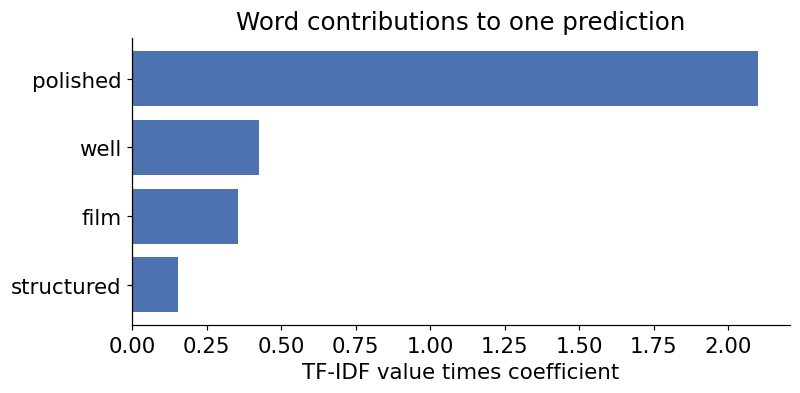

polished , well-structured film . 
Source label=1; positive probability=0.933


In [20]:
example_id = int(np.flatnonzero(dictionary_wrong & logistic_right)[0])
example_text = X_test[example_id]
example_vector = final_logistic["features"].transform([example_text])
contributions = example_vector.toarray()[0] * coefficients
nonzero = np.flatnonzero(contributions)
chosen = nonzero[np.argsort(np.abs(contributions[nonzero]))[-10:]]
chosen = chosen[np.argsort(contributions[chosen])]
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.barh(feature_names[chosen], contributions[chosen],
        color=["#c44e52" if value < 0 else "#4c72b0" for value in contributions[chosen]])
ax.axvline(0, color="black", linewidth=0.7)
ax.set(xlabel="TF-IDF value times coefficient", title="Word contributions to one prediction")
fig.tight_layout()
plt.show()
manual_logit = contributions.sum() + final_logistic["classifier"].intercept_[0]
assert np.isclose(manual_logit, final_logistic.decision_function([example_text])[0])
print(example_text)
print(f"Source label={y_test[example_id]}; positive probability={final_logistic.predict_proba([example_text])[0, 1]:.3f}")


## What to change next

- Use validation examples to decide whether bigrams capture useful patterns such as *not good*.
- Check whether errors cluster by style or subject matter.
- If applying the classifier to another genre, annotate a sample there and validate again.
- For a project, preserve a genuinely untouched final test set. Revising after these classroom comparisons requires new validation data.

Sources: Pang and Lee (2005), *Seeing Stars*; Grimmer, Roberts, and Stewart (2022), *Text as Data*. The dataset's source and label provenance are documented in Class 4's data README.


## Save the figures and numerical results used in the slides

The following cell exports the same values and figures to the lecture folder. This keeps the displayed lecture results aligned with the notebook.


In [21]:
tex_rows = []
for name, result in test_results.items():
    tex_rows.append(
        f"{name} & {result['accuracy']:.3f} & {result['precision']:.3f} & "
        f"{result['recall']:.3f} & {result['F1']:.3f}" + r" \\"
    )
(session_dir / "comparison_rows.tex").write_text(
    r"\newcommand{\ComparisonRows}{" + "\n" + "\n".join(tex_rows) + "\n}\n"
)
macro_values = {
    "CorpusSize": f"{len(texts):,}", "TrainingSize": f"{len(X_train):,}",
    "ValidationSize": f"{len(X_validation):,}", "TestSize": f"{len(X_test):,}",
    "DevelopmentSize": f"{len(X_development):,}", "NBAlpha": f"{best_alpha:g}",
    "LogitC": f"{best_unigram['C']:g}", "SVMC": f"{best_svm_C:g}", "BigramC": f"{best_bigram['C']:g}",
    "CountVocab": f"{len(final_nb['features'].get_feature_names_out()):,}",
    "TFIDFVocab": f"{len(feature_names):,}",
}
(session_dir / "results.tex").write_text(
    "\n".join(r"\newcommand{\%s}{%s}" % (key, value) for key, value in macro_values.items()) + "\n"
)
print("Exported slide results and figures to", session_dir)


Exported slide results and figures to /Users/petrotolochko/Research/04_Teaching/Teaching/CEU_2026/meeting_slides/meeting_05
